# Bivariate Analysis

# Sample Data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 33, 36, 40, 44, 48, 52, 26, 38],
    "Salary": [28000, 34000, 39000, 45000, 51000, 57000, 65000, 73000, 79000, 86000, 36000, 61000],
    "Income": [30000, 35000, 42000, 47000, 53000, 60000, 67000, 75000, 82000, 90000, 38000, 64000],
    "Spending": [12000, 14000, 17000, 18000, 21000, 24000, 27000, 30000, 32000, 35000, 15000, 26000],
    "Department": ["HR", "Sales", "IT", "HR", "IT", "Sales", "IT", "Sales", "IT", "Sales", "HR", "IT"],
    "Product_Category": ["Electronics", "Clothing", "Grocery", "Clothing", "Electronics", "Grocery", "Electronics", "Clothing", "Grocery", "Electronics", "Clothing", "Grocery"],
    "Sales": [2500, 900, 450, 1200, 3100, 550, 4200, 1500, 700, 4700, 1100, 800]
})
print(df.head())

   Age  Salary  Income  Spending Department Product_Category  Sales
0   22   28000   30000     12000         HR      Electronics   2500
1   25   34000   35000     14000      Sales         Clothing    900
2   28   39000   42000     17000         IT          Grocery    450
3   30   45000   47000     18000         HR         Clothing   1200
4   33   51000   53000     21000         IT      Electronics   3100


# 1. Numerical vs Numerical
# Definition
This compares two numerical columns to see whether they change together. The relationship may be positive, negative, or unclear. A scatter plot is a simple way to inspect the pattern.

# Business Example
A company compares employee age and salary to understand salary trends. It can also compare customer income and spending to plan marketing campaigns. These comparisons describe patterns, not proof of cause.

# AI/ML Use
In ML, numerical relationships help us understand possible predictive features. Strongly related inputs may provide useful signals, although correlation alone does not guarantee prediction quality. We inspect the pattern before training.

# Python Example

In [4]:
print(df[["Age", "Salary"]].corr())

             Age    Salary
Age     1.000000  0.998614
Salary  0.998614  1.000000


# Explanation
corr() shows the direction and strength of the linear relationship. In this sample, age and salary tend to rise together. A correlation does not mean age causes higher salary.

# 2. Numerical vs Categorical
Definition
This compares a numerical value across different categories. It helps us see whether groups have different averages or spreads. Box plots and grouped summaries are useful methods.

# Business Example
A business compares salaries across HR, IT, and Sales departments. Managers can identify differences in typical salary levels. The comparison may lead to further investigation rather than an immediate conclusion.

# AI/ML Use
In ML, a category can be useful if the numerical feature varies across groups. Group comparisons also help reveal outliers or data imbalance. These patterns may guide feature engineering.

# Python Example

In [5]:
print(df.groupby("Department")["Salary"].mean().round(2))

Department
HR       36333.33
IT       59000.00
Sales    62500.00
Name: Salary, dtype: float64


# Explanation
groupby() calculates average salary for each department. Compare the values to identify which group has a higher sample average. The result describes only this sample.

# 3. Categorical vs Categorical
Definition
This compares two categorical columns. We count how often each combination occurs. A cross-tabulation makes the counts easy to read.

# Business Example
A retailer compares department and product category to see which combinations appear most often. This can support planning and reporting. Counts should be interpreted with the sample size in mind.

# AI/ML Use
In ML, category combinations can reveal useful patterns or sparse groups. We can also compare a categorical feature against a categorical target. This helps with feature selection and encoding decisions.

# Python Example

In [6]:
print(pd.crosstab(df["Department"], df["Product_Category"]))


Product_Category  Clothing  Electronics  Grocery
Department                                      
HR                       2            1        0
IT                       0            2        3
Sales                    2            1        1


# Explanation
Rows show departments and columns show product categories. Each cell counts records in that combination. Larger counts mean the combination appears more often in this sample.

# 4. Scatter Plot – Age vs Salary
# Definition
A scatter plot displays two numerical variables as points. Each point represents one record. An upward pattern suggests a positive relationship.

# Business Example
An HR analyst plots employee age against salary. The plot makes it easier to notice a trend or unusual records. It does not establish that age directly determines salary.

# AI/ML Use
Scatter plots help inspect numerical relationships before modeling. They can reveal outliers, curved patterns, or groups. Such observations can guide preprocessing and model selection.

# Python Example

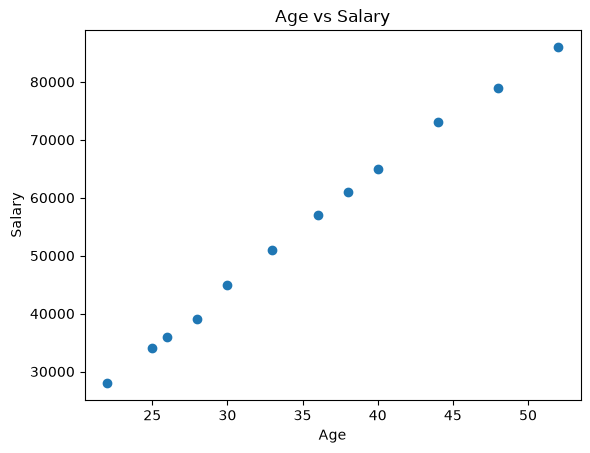

In [7]:
plt.scatter(df["Age"], df["Salary"])
plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Age vs Salary")
plt.show()

# Explanation
Each dot represents an employee. The points generally move upward in this constructed sample, suggesting higher salaries at higher ages. Real datasets may show a less consistent pattern.

# 5. Scatter Plot – Income vs Spending
# Definition
This scatter plot compares income and spending, both numerical variables. It helps show whether spending tends to increase as income increases. The spread of points also matters.

# Business Example
A retail company studies whether higher-income customers spend more. The trend can inform customer segmentation. Other factors may still affect spending.

# AI/ML Use
Income and spending may be predictive features in a customer behavior model. A scatter plot helps check whether their relationship looks approximately linear. It can also highlight unusual customers.

# Python Example

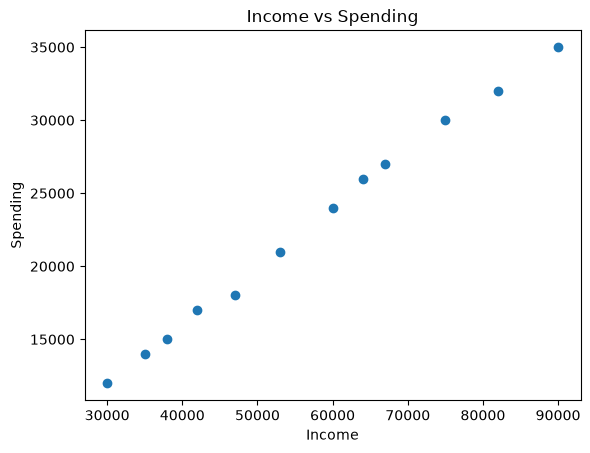

In [8]:
plt.scatter(df["Income"], df["Spending"])
plt.xlabel("Income")
plt.ylabel("Spending")
plt.title("Income vs Spending")
plt.show()

# Explanation
The sample shows an upward trend between income and spending. This indicates a positive association in the example data. It is not enough to claim that income alone determines spending.

# 6. Box Plot – Department vs Salary
# Definition
A box plot compares the distribution of a numerical variable across categories. It shows the median, quartiles, and potential outliers. It is useful when groups have different ranges.

# Business Example
An HR team compares salary distributions in departments. It can see typical salary levels and how widely salaries vary. This helps identify differences worth investigating.

# AI/ML Use
Box plots can show group differences and possible outliers before model training. They help determine whether preprocessing needs to account for unusual values. Group size should be considered when interpreting plots.

# Python Example

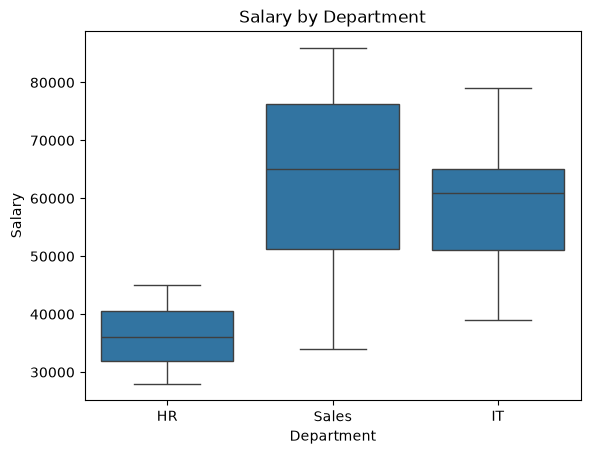

In [9]:
sns.boxplot(data=df, x="Department", y="Salary")
plt.title("Salary by Department")
plt.show()

# Explanation
Each box summarizes salaries within a department. Compare the median lines and box heights to understand differences. Small groups, like these sample departments, give only a limited picture.

# 7. Violin Plot – Department vs Salary
# Definition
A violin plot compares numerical distributions across categories. It combines a distribution shape with group comparison. Wider sections indicate areas with more concentrated values.

# Business Example
A company checks how salaries are distributed within each department. A violin plot can show whether salaries cluster in particular ranges. With very small samples, the smooth shape is only an estimate.

# AI/ML Use
Violin plots help explore feature distributions across groups. They may reveal multiple clusters or differences in spread. This can inform data cleaning and feature analysis.

# Python Example

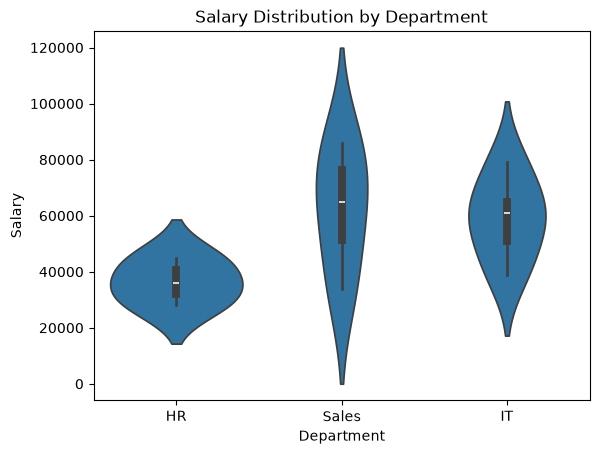

In [10]:
sns.violinplot(data=df, x="Department", y="Salary", inner="box")
plt.title("Salary Distribution by Department")
plt.show()

# Explanation
The plot shows an estimated distribution for each department. Wider regions indicate higher estimated density. Since this example has few records per group, avoid strong conclusions about the shape.

# 8. Grouped Bar Chart – Product Category vs Sales
# Definition
A grouped bar chart compares summarized numerical values across categories. Here we compare total sales for each product category. Aggregation is important because each category has several records.

# Business Example
A retailer compares sales across Electronics, Clothing, and Grocery. Higher totals may indicate stronger sales in the observed records. A fair business comparison may also consider the number of transactions.

# AI/ML Use
Category-level sales summaries can help identify patterns before building a sales forecasting model. Aggregation may reveal important business signals. We should avoid using future sales information as an input when predicting future sales.

# Python Example

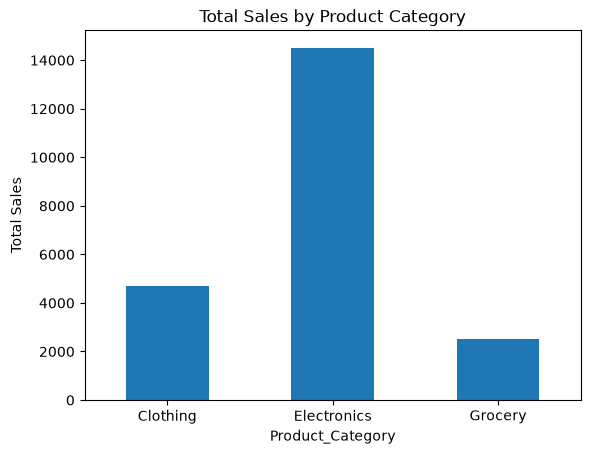

In [11]:
sales_by_category = df.groupby("Product_Category")["Sales"].sum()
sales_by_category.plot(kind="bar")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product Category")
plt.xticks(rotation=0)
plt.show()

# Explanation
groupby() adds sales within each product category. The bars compare the resulting totals. In this sample, Electronics has the largest total sales.

# 9. Cross Tabulation
# Definition
Cross tabulation creates a table of counts for two categorical variables. Each cell represents one category combination. It is useful for comparing how groups overlap.

# Business Example
A retailer checks the number of transactions in each department and product category. The table shows frequent and rare combinations. This can support inventory or sales analysis.

# AI/ML Use
Cross tabs help inspect categorical relationships and class balance. Rare combinations may cause problems for some models. The results can guide grouping or encoding categories.

# Python Example


In [12]:
table = pd.crosstab(df["Department"], df["Product_Category"])
print(table)

Product_Category  Clothing  Electronics  Grocery
Department                                      
HR                       2            1        0
IT                       0            2        3
Sales                    2            1        1


# Explanation
The table counts records for each department–category pair. Read across a row to compare categories within a department. These counts describe the example dataset, not a population-wide trend.